# Attention: decidir qué contexto usar

**Materiales desarrollados por Matías Barreto, 2026**

**Tecnicatura Superior en Ciencias de Datos e IA, IFTS N.º 24**
* **Nomenclatura oficial:** Procesamiento de Lenguaje Natural
* **Nombre de trabajo:** Laboratorio de PLN: Analítica, Textos y Cultura

---
| | |
|---|---|
| **Problema** | Un token necesita combinar partes relevantes del contexto sin depender solo de la distancia. |
| **Producto** | Una matriz de atención, una máscara causal y una explicación de por qué GPT es decoder-only. |
| **Recursos** | Python, NumPy, Matplotlib e ipywidgets; no se descarga ni entrena un modelo. |

Una red puede transformar vectores, pero todavía falta decidir qué otros vectores usar para representar cada token. Attention convierte esa decisión en una matriz visible.

**¿Cómo calcula un Transformer qué partes del contexto pesan para cada token y por qué GPT no puede mirar los tokens futuros?**

> **Cómo se trabaja.** Explorás el mecanismo con una oración de cuatro tokens. Los números son sintéticos y sirven para inspeccionar operaciones, no para evaluar un modelo de lenguaje.

In [1]:
import numpy as np
import ipywidgets as widgets

import utils

np.set_printoptions(precision=2, suppress=True)

## 1. Cada token puede consultar el contexto

Usamos la oración El archivo guarda datos. Cada token tiene un vector de dos dimensiones. Primero hacemos una versión mínima: el vector que consulta también funciona como clave y valor. Después separaremos esos papeles.

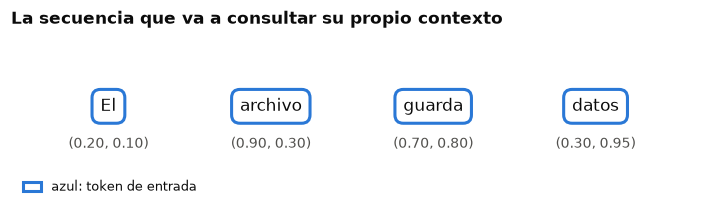

In [2]:
tokens = ["El", "archivo", "guarda", "datos"]
entradas = np.array([
    [0.20, 0.10],
    [0.90, 0.30],
    [0.70, 0.80],
    [0.30, 0.95],
])

notas = []
for vector in entradas:
    notas.append(f"({vector[0]:.2f}, {vector[1]:.2f})")

estilos = {"token": (utils.AZUL, "azul: token de entrada")}
utils.dibujar_fichas(
    piezas=tokens,
    clases=["token"] * len(tokens),
    estilos=estilos,
    titulo="La secuencia que va a consultar su propio contexto",
    notas=notas,
)

## 2. Del producto punto a los pesos de atención

Para un token que consulta, calculamos su producto punto con todos los tokens. Softmax transforma esos puntajes en pesos positivos que suman uno. El vector de contexto será la suma ponderada de los vectores de entrada.

token que consulta: guarda
puntajes: [0.22 0.87 1.13 0.97]
pesos: [0.13 0.25 0.33 0.28]
vector de contexto: [0.57 0.62]


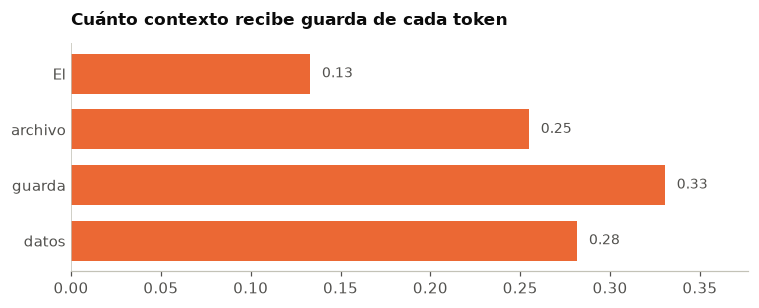

In [3]:
def softmax(valores: np.ndarray) -> np.ndarray:
    """Convierte puntajes en pesos positivos que suman uno.

    Args:
        valores: Puntajes para los tokens considerados.

    Returns:
        Pesos normalizados en el mismo orden.
    """
    valores_estables = valores - valores.max()
    exponenciales = np.exp(valores_estables)
    return exponenciales / exponenciales.sum()


indice_consulta = 2
consulta = entradas[indice_consulta]
puntajes = entradas @ consulta
pesos_atencion = softmax(puntajes)
vector_contexto = pesos_atencion @ entradas

print(f"token que consulta: {tokens[indice_consulta]}")
print(f"puntajes: {puntajes}")
print(f"pesos: {pesos_atencion}")
print(f"vector de contexto: {vector_contexto}")
utils.dibujar_barras(
    nombres=tokens,
    valores=pesos_atencion,
    titulo="Cu\u00e1nto contexto recibe guarda de cada token",
    color=utils.NARANJA,
)

> **Para mirar.** Los pesos no son una explicación lingüística ni una prueba de que el modelo entendió la oración. En este ejemplo muestran una regla matemática: guarda combina todos los vectores, pero no en la misma proporción.

## 3. Una fila por token forma una matriz

Repetimos el cálculo para cada token. La fila indica quién consulta; la columna, qué token se considera. Cada fila suma uno porque softmax normaliza la distribución de pesos.

sumas por fila: [1. 1. 1. 1.]


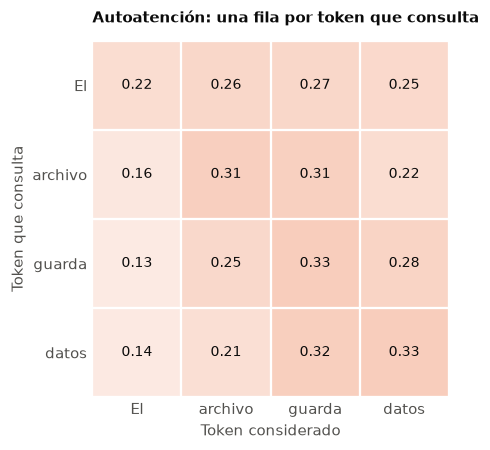

In [4]:
puntajes_completos = entradas @ entradas.T
matriz_atencion = np.zeros_like(puntajes_completos)

for fila in range(len(tokens)):
    matriz_atencion[fila] = softmax(puntajes_completos[fila])

sumas_por_fila = matriz_atencion.sum(axis=1)
print(f"sumas por fila: {sumas_por_fila}")
utils.dibujar_mapa_de_calor(
    matriz=matriz_atencion,
    filas=tokens,
    columnas=tokens,
    titulo="Autoatenci\u00f3n: una fila por token que consulta",
    color=utils.NARANJA,
)

> **Para mirar.** Cada fila distribuye un presupuesto total de 1.00 entre los tokens disponibles. La matriz hace visible algo que una secuencia de productos punto escondería: cada token tiene su propia distribución de atención.

## 4. GPT necesita ocultar el futuro

Un modelo que predice el próximo token no puede usar una palabra que todavía no existe en el texto generado. La máscara causal reemplaza los puntajes futuros por un valor tan bajo que softmax les asigna peso cero.

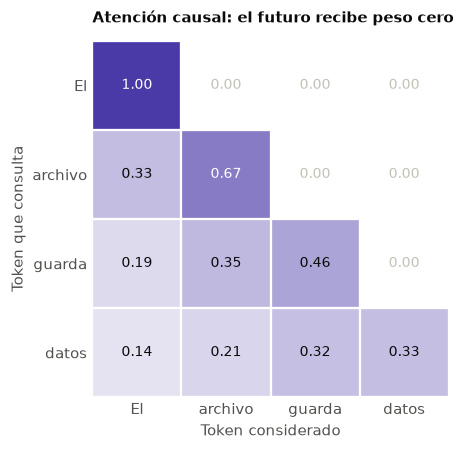

In [5]:
def atencion_causal(puntajes: np.ndarray) -> np.ndarray:
    """Aplica una mascara causal y normaliza cada fila.

    Args:
        puntajes: Matriz cuadrada de puntajes de atencion.

    Returns:
        Matriz de pesos que no usa columnas futuras.
    """
    puntajes_enmascarados = puntajes.copy()
    for fila in range(len(puntajes_enmascarados)):
        puntajes_enmascarados[fila, fila + 1:] = -1e9
    pesos = np.zeros_like(puntajes_enmascarados)
    for fila in range(len(pesos)):
        pesos[fila] = softmax(puntajes_enmascarados[fila])
    return pesos


matriz_causal = atencion_causal(puntajes_completos)
utils.dibujar_mapa_de_calor(
    matriz=matriz_causal,
    filas=tokens,
    columnas=tokens,
    titulo="Atenci\u00f3n causal: el futuro recibe peso cero",
    color=utils.VIOLETA,
)

> **Para mirar.** En la primera fila, El solo puede atender a El; en la última, datos puede usar toda la oración anterior. Esta restricción es la conexión directa con la predicción del próximo token que veremos al trabajar con GPT-2.

### Experimentar con una fila de la matriz

Elegí el token que consulta. El control cambia la barra; el mapa de calor causal de arriba queda como alternativa estática para leer el mismo mecanismo fuera de Jupyter.

interactive(children=(Dropdown(description='Token:', index=2, options=(0, 1, 2, 3), value=2), Output()), _dom_…

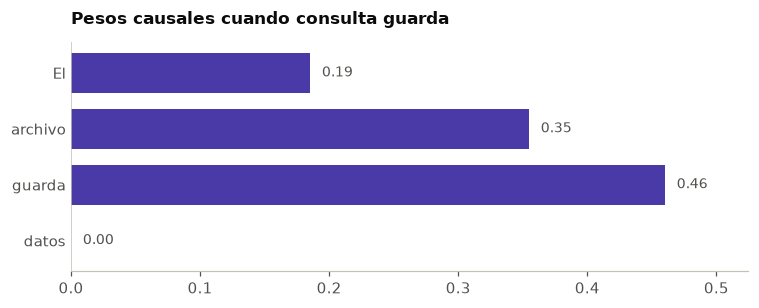

In [6]:
def mostrar_fila(indice: int) -> None:
    """Muestra una fila de la matriz causal como barras.

    Args:
        indice: Posicion del token que consulta.
    """
    utils.dibujar_barras(
        nombres=tokens,
        valores=matriz_causal[indice],
        titulo=f"Pesos causales cuando consulta {tokens[indice]}",
        color=utils.VIOLETA,
    )


selector = widgets.Dropdown(
    options=list(range(len(tokens))),
    value=2,
    description="Token:",
)
widgets.interact(mostrar_fila, indice=selector)

# Alternativa estatica si el widget no aparece en el visor.
mostrar_fila(2)

## 5. Consultas, claves y valores se aprenden por separado

En un Transformer real, los vectores de entrada se proyectan en tres papeles: **query** pregunta qué busca el token; **key** ofrece una clave para compararlo; **value** aporta la información que se combina. Esas proyecciones usan pesos aprendibles, como la neurona del cuaderno anterior.

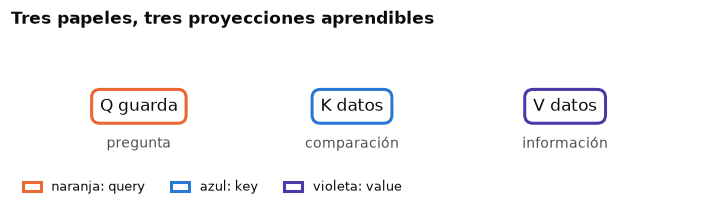

Q de guarda: [0.78 0.78]
K de datos: [0.49 1.02]
V de datos: [-0.04  0.97]


In [7]:
consulta_proyectada = entradas @ np.array([[1.0, 0.2], [0.1, 0.8]])
claves_proyectadas = entradas @ np.array([[0.7, -0.1], [0.3, 1.1]])
valores_proyectados = entradas @ np.array([[0.5, 0.4], [-0.2, 0.9]])

estilos_qkv = {
    "consulta": (utils.NARANJA, "naranja: query"),
    "clave": (utils.AZUL, "azul: key"),
    "valor": (utils.VIOLETA, "violeta: value"),
}
utils.dibujar_fichas(
    piezas=["Q guarda", "K datos", "V datos"],
    clases=["consulta", "clave", "valor"],
    estilos=estilos_qkv,
    titulo="Tres papeles, tres proyecciones aprendibles",
    notas=["pregunta", "comparaci\u00f3n", "informaci\u00f3n"],
)
print("Q de guarda:", consulta_proyectada[2])
print("K de datos:", claves_proyectadas[3])
print("V de datos:", valores_proyectados[3])

## 6. Un bloque que se repite

Atención no es todo el Transformer. Un bloque decoder-only combina embeddings de token y posición, atención causal, conexiones residuales, normalización y una red feed-forward. GPT-2 apila muchos bloques de este tipo y termina con una capa que puntúa el próximo token posible.

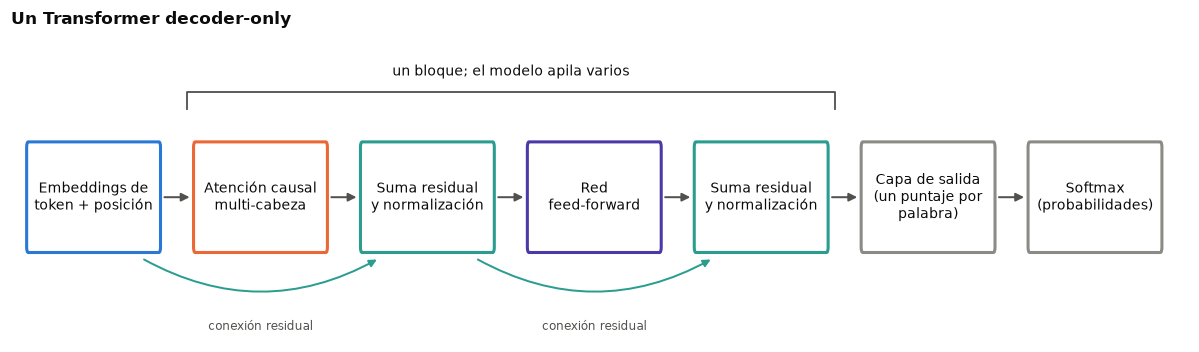

In [8]:
utils.dibujar_bloque_transformer()

### Microlaboratorio 1 — Reconstruir una máscara causal

**Tarea.** Marcá como inaccesibles los tokens futuros de archivo.  
**Producto.** Una fila causal con ceros después de la posición de archivo.

| Línea | Qué tiene que quedar | Con qué |
|---|---|---|
| (1) | la posición de archivo | el entero 1 |
| (2) | pesos causales para esa fila | matriz_causal e indice_archivo |

> **Ayuda 1.** En el mapa causal, archivo es la segunda fila.  
> **Ayuda 2.** Indexar una matriz por fila devuelve un vector.

In [9]:
indice_archivo = 0  # COMPLETAR (1)
pesos_archivo = np.zeros(len(tokens))  # COMPLETAR (2)

print(pesos_archivo)
utils.comprobar(
    np.isclose(pesos_archivo.sum(), 1.0)
    and np.allclose(pesos_archivo[2:], 0.0),
    "revisa la fila de archivo: solo puede usar El y archivo.",
)

[0. 0. 0. 0.]
Todavia no. revisa la fila de archivo: solo puede usar El y archivo.


## Qué te llevás

- Attention convierte similitudes entre vectores en pesos que determinan cuánto aporta cada token al contexto de otro.
- Una matriz de atención tiene una distribución por token que consulta; una celda aislada no explica por sí sola una decisión lingüística.
- La máscara causal impide usar el futuro y permite que un Transformer decoder-only se use para predecir el próximo token.

**Sigue:** el bloque completo, con varias cabezas, y cómo termina en la distribución del próximo token (03); después, la atención de un modelo real (04).